# Exercise 3: Hierarchical clustering

Same images and embeddings as Exercise 1, layer 6.

## 1. Load the dataset

In [66]:
import numpy as np
import matplotlib.pyplot as plt

from datasets import load_dataset
from huggingface_hub import hf_hub_download

DATA = "blanchon/UC_Merced"

ds = load_dataset(DATA, split="train")
class_names = ds.features["label"].names
labels = np.array(ds["label"])

print(f"{len(ds)} images, {len(class_names)} classes")

2100 images, 21 classes


## 2. Embeddings

In [67]:
order = np.asarray(sorted(range(len(ds)), key=lambda i: (class_names[labels[i]], i)))
y_all = labels[order] + 1                      # 1-based, as in the embeddings

rng = np.random.default_rng(0)
train_idx, test_idx = [], []
for label in range(1, len(class_names) + 1):
    idx = np.where(y_all == label)[0]
    rng.shuffle(idx)
    n_test = max(1, int(round(len(idx) * 0.2)))
    test_idx += list(idx[:n_test])
    train_idx += list(idx[n_test:])

train_idx, test_idx = np.asarray(train_idx), np.asarray(test_idx)

print(f"train {len(train_idx)} / test {len(test_idx)}")

train 1680 / test 420


## 3. Align the training images

In [68]:
def to_rgb(row):
    im = row["image"].convert("RGB")
    if im.size != (256, 256):
        im = im.resize((256, 256))
    return np.asarray(im)

X_train_rgb = np.stack([to_rgb(ds[int(i)]) for i in order[train_idx]])
y_train = y_all[train_idx]

print(X_train_rgb.shape, y_train.shape)

(1680, 256, 256, 3) (1680,)


## 4. Load the embeddings

In [69]:
REPO = "MustafaArikan/vit_embeddings_uc_merced_layers"
path = hf_hub_download(REPO, "vit_embeddings_uc_merced_layers.npz", repo_type="dataset")
d = np.load(path)

LAYER = 6
E = d[f"E_train_l{LAYER}"]

print(E.shape)

(1680, 768)


## 5. TODO: calculate the similarity matrix using the layer 6 embedding

In [70]:
from sklearn.metrics.pairwise import cosine_similarity

sim_matrix = cosine_similarity(E)

## 6. TODO: show the most dissimilar pair and the most similar pair, using cosine similarity (without considering duplicates)

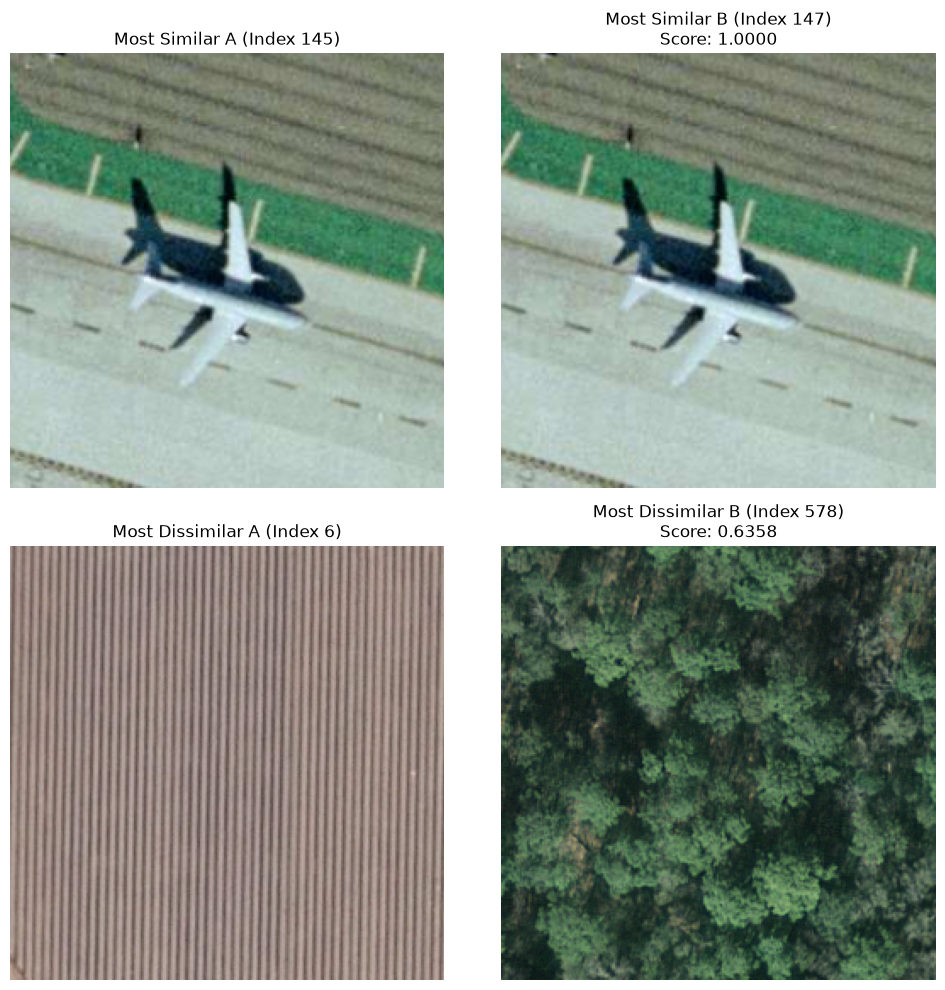

In [71]:
import numpy as np

# only consider the upper triangle
row_indices, col_indices = np.triu_indices_from(sim_matrix, k=1)

scores = sim_matrix[row_indices, col_indices]

max_idx = np.argmax(scores)
min_idx = np.argmin(scores)

# most similar
idx_sim1, idx_sim2 = (row_indices[max_idx], col_indices[max_idx])
# most dissimilar
idx_dissim1, idx_dissim2 = (row_indices[min_idx], col_indices[min_idx])

fig, axes = plt.subplots(2, 2, figsize=(10, 10))

axes[0, 0].imshow(X_train_rgb[idx_sim1])
axes[0, 0].set_title(f"Most Similar A (Index {idx_sim1})")
axes[0, 0].axis("off")

axes[0, 1].imshow(X_train_rgb[idx_sim2])
axes[0, 1].set_title(f"Most Similar B (Index {idx_sim2})\nScore: {scores[max_idx]:.4f}")
axes[0, 1].axis("off")

axes[1, 0].imshow(X_train_rgb[idx_dissim1])
axes[1, 0].set_title(f"Most Dissimilar A (Index {idx_dissim1})")
axes[1, 0].axis("off")

axes[1, 1].imshow(X_train_rgb[idx_dissim2])
axes[1, 1].set_title(f"Most Dissimilar B (Index {idx_dissim2})\nScore: {scores[min_idx]:.4f}")
axes[1, 1].axis("off")

plt.tight_layout()
plt.show()


## 7. TODO: do hierarchical clustering, experiment with parameter settings, visualize and find a meaningful cluster

* Ward + Eucledian is the best

In [72]:
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

def hierarchical_clustering(linkage_method, distance_metric):

    # linkage matrix
    Z = linkage(E, method=linkage_method, metric=distance_metric)

    plt.figure(figsize=(15, 6))
    plt.title(f"Hierarchical Clustering (Method: {linkage_method}, Distance Metric: {distance_metric})")
    plt.xlabel("Sample Index")
    plt.ylabel("Distance")

    # Don't show every leaf so the plot stays readable
    dendrogram(Z, truncate_mode='lastp', p=100, leaf_rotation=90.)

    plt.show()

    return Z

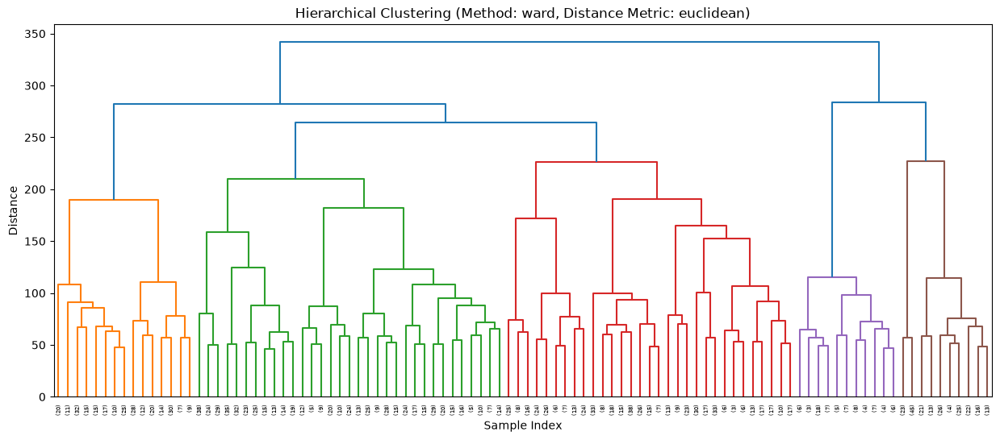

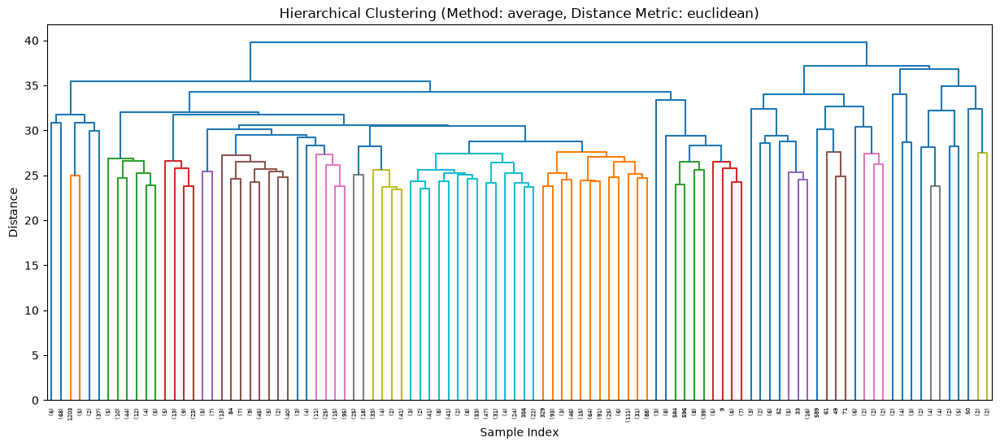

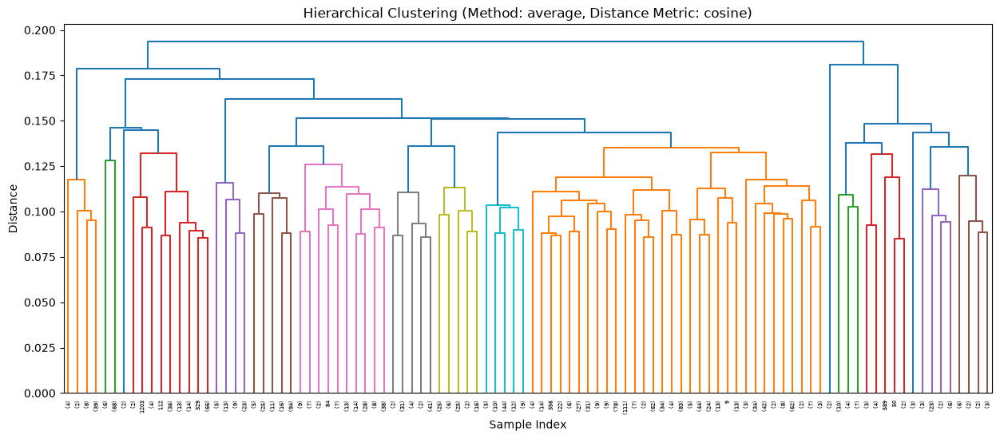

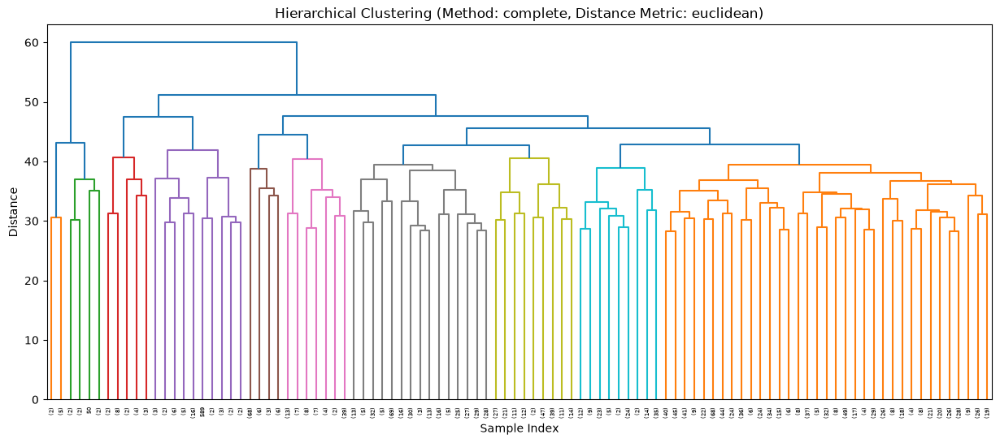

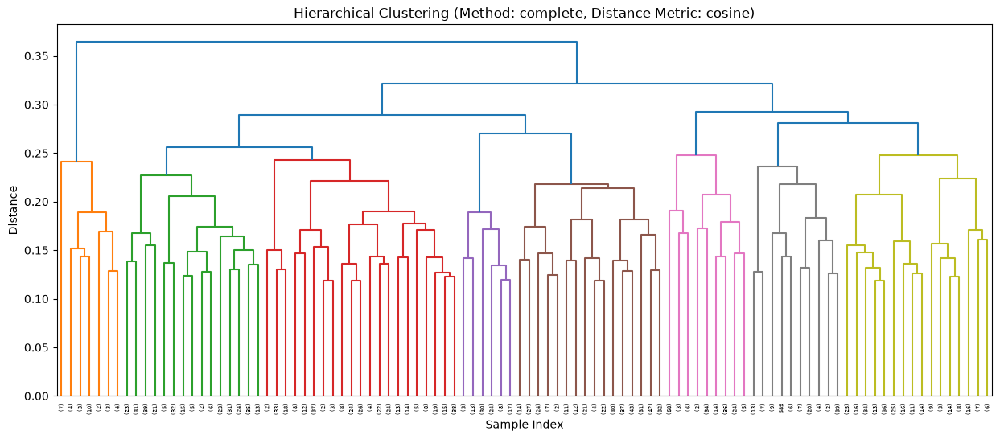

In [73]:
metrics = ["euclidean", "cosine"]
methods = ["ward", "average", "complete"]

linkage_matrixes = {}

for method in methods:
    for metric in metrics:
        if (method != "ward" or metric != "cosine"): # these two dont work together
            linkage_matrixes[f"{method},{metric}"] = hierarchical_clustering(method, metric)

Total clusters formed at distance 150: 15



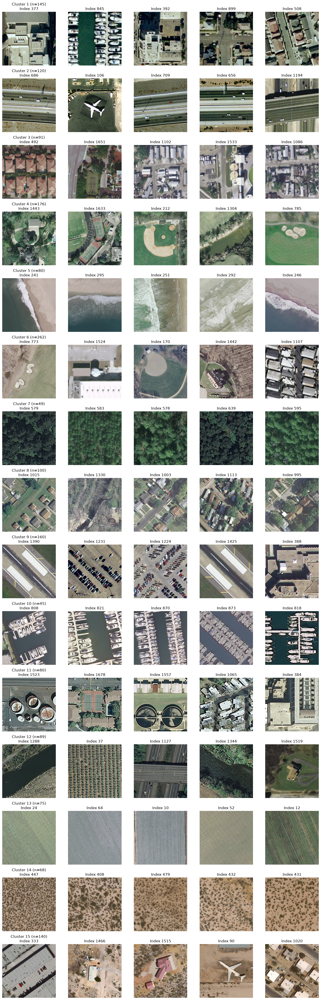

In [76]:
CUT_DISTANCE = 150
SAMPLES_PER_CLUSTER = 5

# Cut at a distance of 150
cluster_labels = fcluster(linkage_matrixes["ward,euclidean"], t=CUT_DISTANCE, criterion='distance')

unique_clusters = np.unique(cluster_labels)
num_clusters = len(unique_clusters)

print(f"Total clusters formed at distance {CUT_DISTANCE}: {num_clusters}\n")

fig, axes = plt.subplots(num_clusters, SAMPLES_PER_CLUSTER, figsize=(15, 3 * num_clusters))

for row_idx, cluster_id in enumerate(unique_clusters):       
    cluster_indices = np.where(cluster_labels == cluster_id)[0]    
    
    num_to_plot = min(SAMPLES_PER_CLUSTER, len(cluster_indices))
    random_sample_indices = np.random.choice(cluster_indices, num_to_plot, replace=False)
    
    for col_idx in range(SAMPLES_PER_CLUSTER):
        ax = axes[row_idx, col_idx]
        
        if col_idx < num_to_plot:
            img_idx = random_sample_indices[col_idx]
            ax.imshow(X_train_rgb[img_idx])            
           
            if col_idx == 0:
                ax.set_title(f"Cluster {cluster_id} (n={len(cluster_indices)})\nIndex {img_idx}")
            else:
                ax.set_title(f"Index {img_idx}")        
       
        ax.axis("off")

plt.tight_layout()
plt.show()

All clusters look very good, especially 5,7,10